In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 선형 회귀 모델
from sklearn.linear_model import LinearRegression

In [3]:
# * 과거 데이터 준비
time = np.array([10, 15, 20, 25, 30, 35, 40, 45, 50, 55])                # 운동 시간 (예시 입력 데이터)
calorie = np.array([55, 78, 108, 127, 160, 177, 212, 235, 263, 294])     # 소모 칼로리 (예시 출력 데이터)

In [4]:
# * 모델 생성 및 학습
md = LinearRegression()
md.fit(time.reshape(-1, 1), calorie)

LinearRegression()

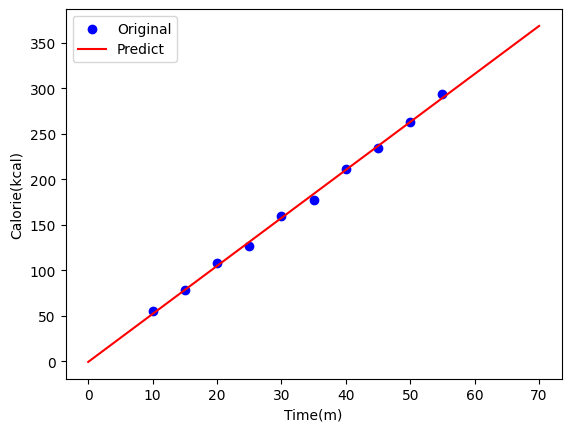

In [ ]:
# 실제값-예측값 그래프 그리기
test = np.arange(0, 71, 5)              # [0, 5, 10, ..., 65, 70] -> 15개
pred = md.predict(test.reshape(-1, 1))  # 15개의 데이터에 대한 각 예측값 불러오기

plt.scatter(time, calorie, color='blue', label='Original')
plt.plot(test, pred, color='red', label='Predict')

plt.xlabel('Time(m)')
plt.ylabel('Calorie(kcal)')
plt.legend()
plt.show()

# train_test_split() :: 학습용 데이터 / 테스트용 데이터 분리
*   학습용 데이터 :: 머신러닝 모델이 규칙/패턴 파악하게끔 학습하는 데에 사용
*   테스트용 데이터 :: 머신러닝 모델이 잘 작동하는지 확인하는 데에 사용
---
*   제가 수업할 때 쓰는 예제 -> 학습용 데이터
*   실습문제로 쓰는 예제    -> 테스트용 데이터

In [5]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    time,
    calorie,
    test_size = 0.2,
    random_state = 42
)
# test_size :: "원본 데이터 중 몇 %의 비중을 테스트 데이터로 고를 것인가"
#      (test_size 설정 안하면, 0.25 값으로 설정)
# random_state :: 테스트 데이터 선택 방식에 대해 설정 (42로 설정하면, 고정값이 선택)

# 데이터 간 상관관계 해치지 않게끔 선택

# time = x_train + x_test
print('운동시간 총 데이터:', time)
print(x_train)
print(x_test)

# calorie = y_train + y_test
print('소모 칼로리 총 데이터:',calorie)
print(y_train)
print(y_test)

운동시간 총 데이터: [10 15 20 25 30 35 40 45 50 55]
[35 10 45 20 55 30 25 40]
[50 15]
소모 칼로리 총 데이터: [ 55  78 108 127 160 177 212 235 263 294]
[177  55 235 108 294 160 127 212]
[263  78]


# score() :: 머신러닝 모델 성능 평가/테스트
"머신러닝 모델이 얼마나 잘 예측하는지를 점수로 매김"

In [ ]:
model_score = md.score(x_test.reshape(-1, 1), y_test)
# x_test로 시험 문제를 주고, y_test로 채점 수행
# (ex) 문제 :: 50분 운동하면, 몇 칼로리가 소모될까?
#      정답 :: 263 kcal

print('성능 점수:', model_score*100)
# 머신러닝 모델에 잘 학습시켰는지 확인하기 위해 필요

성능 점수: 99.99781707103574


# mean_absolute_error() :: 평균 절대 오차 계산

In [ ]:
# 오차값 = "실제값(정답) - 예측값(머신러닝의 답)"의 간극/절대값
#      => mean_absolute_error() :: 위 오차값들에 대해 평균을 낸 값

print('[문제 양식] 00분동안 운동을 하면, 소모되는 칼로리는 몇 kcal인가?')
print('1번 문제:', x_test[0], '분')
print('2번 문제:', x_test[1], '분')
print()

print('[머신러닝이 제시한 답]')
print('1번 문제의 답:', md.predict(x_test[0].reshape(-1, 1)))
print('2번 문제의 답:', md.predict(x_test[1].reshape(-1, 1)))
print()

print('[문제에 대한 정답]')
print('1번 문제 정답:', y_test[0])
print('2번 문제 정답:', y_test[1])
print()

# ((1번 문제의 오차값) + (2번 문제의 오차값)) / (문제의 수, 2)
#    => mean_absolute_error() 결과값

[문제 양식] 00분동안 운동을 하면, 소모되는 칼로리는 몇 kcal인가?
1번 문제: 50 분
2번 문제: 15 분

[머신러닝이 제시한 답]
1번 문제의 답: [263.23636364]
2번 문제의 답: [78.56363636]

[문제에 대한 정답]
1번 문제 정답: 263
2번 문제 정답: 78



In [ ]:
from sklearn.metrics import mean_absolute_error

# 실제값(y_test), 예측값 준비(아래의 pred)
pred = md.predict(x_test.reshape(-1, 1))

error = mean_absolute_error(y_test, pred)
print(error, 'kcal')    # 0.4 kcal

# 평균적으로, 0.4kcal 정도의 오차가 발생하고 있음

0.4000000000000128 kcal
